# SWAN-SF Tabular Baselines: Logistic Regression & XGBoost

In [2]:
# Configure project paths and load prepared CSVs
from pathlib import Path
import pandas as pd
import sys, os

sys.path.append(os.path.abspath("../scripts"))

from data_utils import find_project_root, split_features_labels
from preprocessing import scale_tabular_data
from metrics import compute_metrics, sweep_thresholds, format_metrics

PROJECT_ROOT = find_project_root(Path.cwd())
PREPARED_DIR = PROJECT_ROOT / "data" / "prepared"
print("Using project root:", PROJECT_ROOT)
print("Prepared data dir:", PREPARED_DIR)

train_path = PREPARED_DIR / "swansf_tabular_train.csv"
val_path = PREPARED_DIR / "swansf_tabular_val.csv"
test_path = PREPARED_DIR / "swansf_tabular_test.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

train_df.shape, val_df.shape, test_df.shape

Using project root: /Users/chintan/Drive/Projects/solar-flare-classification
Prepared data dir: /Users/chintan/Drive/Projects/solar-flare-classification/data/prepared


((78211, 26), (19553, 26), (331185, 26))

In [3]:
# Inspect label balance
def summarize_labels(df, split_name: str):
    counts = df["label"].value_counts().sort_index()
    total = counts.sum()
    pos = counts.get(1, 0)
    neg = counts.get(0, 0)
    print(f"{split_name}: total={total}, pos={pos} ({pos/total:.2%}), neg={neg} ({neg/total:.2%})")

summarize_labels(train_df, "Train")
summarize_labels(val_df, "Validation")
summarize_labels(test_df, "Test")

Train: total=78211, pos=38218 (48.87%), neg=39993 (51.13%)
Validation: total=19553, pos=9555 (48.87%), neg=9998 (51.13%)
Test: total=331185, pos=6234 (1.88%), neg=324951 (98.12%)


In [4]:
import numpy as np

SELECTED_BASE_FEATURES = ("SAVNCPP", "ABSNJZH", "R_VALUE", "EPSZ", "TOTFZ")

X_train, y_train = split_features_labels(train_df, selected_features=SELECTED_BASE_FEATURES)
X_val, y_val = split_features_labels(val_df, selected_features=SELECTED_BASE_FEATURES)
X_test, y_test = split_features_labels(test_df, selected_features=SELECTED_BASE_FEATURES)

X_train_s, X_val_s, X_test_s, scaler = scale_tabular_data(X_train, X_val, X_test)
X_train_s.shape, X_val_s.shape, X_test_s.shape

((78211, 20), (19553, 20), (331185, 20))

## Logistic Regression

In [5]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(
    class_weight="balanced",
    max_iter=200,
    solver="lbfgs",
    n_jobs=-1,
)
logreg.fit(X_train_s, y_train)

val_scores_lr = logreg.predict_proba(X_val_s)[:, 1]
best_lr_val, lr_threshold_grid = sweep_thresholds(y_val, val_scores_lr)
best_lr_val

/Users/chintan/Drive/Projects/solar-flare-classification/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)


{'threshold': 0.49999999999999994,
 'roc_auc': 0.9922724785668801,
 'pr_auc': 0.990117534514546,
 'accuracy': 0.9642510100751803,
 'precision': 0.953688524590164,
 'recall': 0.9741496598639455,
 'f1': 0.9638105099663473,
 'tpr': 0.9741496598639455,
 'fpr': 0.045209041808361675,
 'tss': 0.9289406180555838,
 'hss': 0.9284992861331545,
 'tn': 9546,
 'fp': 452,
 'fn': 247,
 'tp': 9308,
 'y_pred': array([0, 1, 0, ..., 0, 0, 0], shape=(19553,))}

In [6]:
# Evaluate logistic regression on validation and test splits using the best threshold
from IPython.display import display

val_metrics_lr = compute_metrics(y_val, val_scores_lr, threshold=best_lr_val["threshold"])

test_scores_lr = logreg.predict_proba(X_test_s)[:, 1]
test_metrics_lr = compute_metrics(y_test, test_scores_lr, threshold=best_lr_val["threshold"])

# Standardized metrics at fixed threshold=0.5 (for cross-notebook consistency)
METRIC_KEYS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'hss', 'tss', 'fpr', 'tpr']
def select_metrics(metrics, keys=METRIC_KEYS):
    return {k: metrics[k] for k in keys if k in metrics}

val_metrics_lr_fixed = compute_metrics(y_val, val_scores_lr, threshold=0.5)
test_metrics_lr_fixed = compute_metrics(y_test, test_scores_lr, threshold=0.5)

TABLE_KEYS = ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "tss", "hss", "fpr", "tpr"]
def table_row(metrics, keys=TABLE_KEYS):
    rounded = format_metrics(metrics, decimals=3)
    return {k: rounded[k] for k in keys if k in rounded}

lr_best_table = pd.DataFrame(
    [
        table_row(val_metrics_lr),
        table_row(test_metrics_lr),
    ],
    index=["Validation (best threshold)", "Test (best threshold)"],
)

lr_fixed_table = pd.DataFrame(
    [
        table_row({"threshold": 0.5, **select_metrics(val_metrics_lr_fixed)}),
        table_row({"threshold": 0.5, **select_metrics(test_metrics_lr_fixed)}),
    ],
    index=["Validation (@0.5)", "Test (@0.5)"],
)

print("Logistic Regression Metrics (Best Validation Threshold)")
display(lr_best_table)

print("Logistic Regression Metrics (Fixed Threshold = 0.5)")
display(lr_fixed_table)


Logistic Regression Metrics (Best Validation Threshold)


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tss,hss,fpr,tpr
Validation (best threshold),0.5,0.964,0.954,0.974,0.964,0.992,0.990,0.929,0.928,0.045,0.974
Test (best threshold),0.5,0.794,0.078,0.916,0.143,0.928,0.204,0.707,0.112,0.209,0.916


Logistic Regression Metrics (Fixed Threshold = 0.5)


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tss,hss,fpr,tpr
Validation (@0.5),0.5,0.964,0.954,0.974,0.964,0.992,0.990,0.929,0.928,0.045,0.974
Test (@0.5),0.5,0.794,0.078,0.916,0.143,0.928,0.204,0.707,0.112,0.209,0.916


## XGBoost (gradient boosted trees)

In [ ]:
from xgboost import XGBClassifier

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count if pos_count > 0 else 1.0

xgb = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    n_jobs=-1,
    random_state=42,
)

xgb.fit(X_train, y_train)

val_scores_xgb = xgb.predict_proba(X_val)[:, 1]
best_xgb_val, xgb_threshold_grid = sweep_thresholds(y_val, val_scores_xgb)
best_xgb_val

{'threshold': 0.5499999999999999,
 'roc_auc': 0.998604378123139,
 'pr_auc': 0.9983906003881621,
 'accuracy': 0.9817419321843195,
 'precision': 0.9752997106242249,
 'recall': 0.9876504447933019,
 'f1': 0.9814362227653268,
 'tpr': 0.9876504447933019,
 'fpr': 0.023904780956191238,
 'tss': 0.9637456638371107,
 'hss': 0.9634753577110012,
 'tn': 9759,
 'fp': 239,
 'fn': 118,
 'tp': 9437,
 'y_pred': array([0, 1, 0, ..., 0, 0, 0], shape=(19553,))}

In [8]:
val_metrics_xgb = compute_metrics(y_val, val_scores_xgb, threshold=best_xgb_val["threshold"])

test_scores_xgb = xgb.predict_proba(X_test)[:, 1]
test_metrics_xgb = compute_metrics(y_test, test_scores_xgb, threshold=best_xgb_val["threshold"])

# Standardized metrics at fixed threshold=0.5 (for cross-notebook consistency)
METRIC_KEYS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc', 'hss', 'tss', 'fpr', 'tpr']
def select_metrics(metrics, keys=METRIC_KEYS):
    return {k: metrics[k] for k in keys if k in metrics}

val_metrics_xgb_fixed = compute_metrics(y_val, val_scores_xgb, threshold=0.5)
test_metrics_xgb_fixed = compute_metrics(y_test, test_scores_xgb, threshold=0.5)

TABLE_KEYS = ["threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "tss", "hss", "fpr", "tpr"]
def table_row(metrics, keys=TABLE_KEYS):
    rounded = format_metrics(metrics, decimals=3)
    return {k: rounded[k] for k in keys if k in rounded}

xgb_best_table = pd.DataFrame(
    [
        table_row(val_metrics_xgb),
        table_row(test_metrics_xgb),
    ],
    index=["Validation (best threshold)", "Test (best threshold)"],
)

xgb_fixed_table = pd.DataFrame(
    [
        table_row({"threshold": 0.5, **select_metrics(val_metrics_xgb_fixed)}),
        table_row({"threshold": 0.5, **select_metrics(test_metrics_xgb_fixed)}),
    ],
    index=["Validation (@0.5)", "Test (@0.5)"],
)

print("XGBoost Metrics (Best Validation Threshold)")
display(xgb_best_table)

print("XGBoost Metrics (Fixed Threshold = 0.5)")
display(xgb_fixed_table)


XGBoost Metrics (Best Validation Threshold)


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tss,hss,fpr,tpr
Validation (best threshold),0.55,0.982,0.975,0.988,0.981,0.999,0.998,0.964,0.963,0.024,0.988
Test (best threshold),0.55,0.933,0.193,0.802,0.311,0.960,0.370,0.737,0.289,0.064,0.802


XGBoost Metrics (Fixed Threshold = 0.5)


,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,tss,hss,fpr,tpr
Validation (@0.5),0.5,0.981,0.971,0.99,0.980,0.999,0.998,0.962,0.961,0.028,0.99
Test (@0.5),0.5,0.927,0.181,0.82,0.296,0.960,0.370,0.749,0.274,0.071,0.82


Logistic Regression - Validation


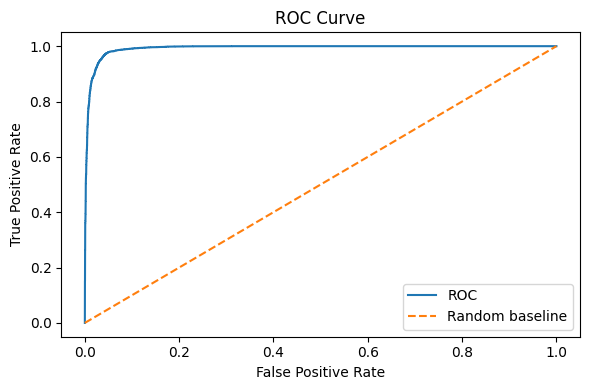

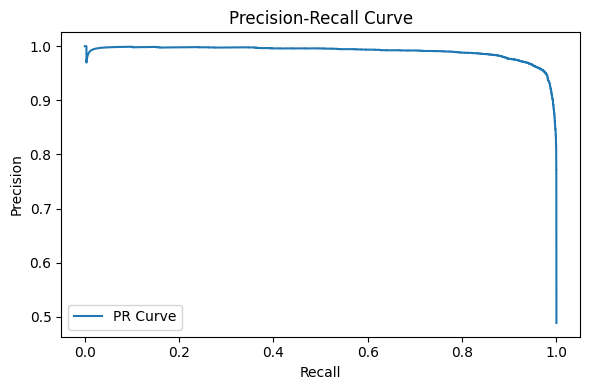

Logistic Regression - Test


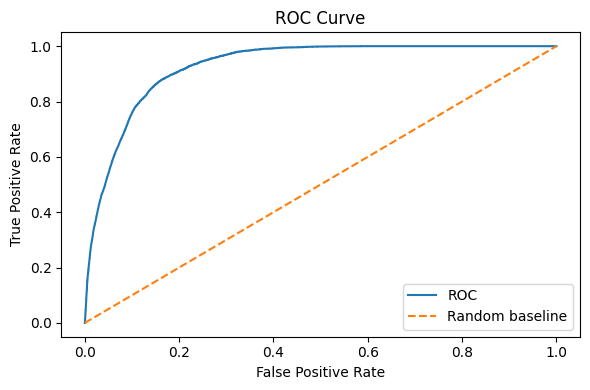

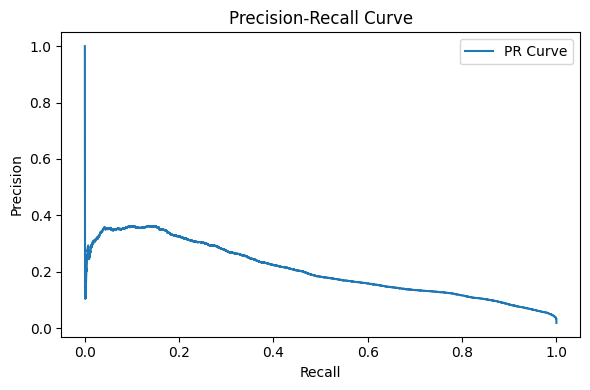

XGBoost - Validation


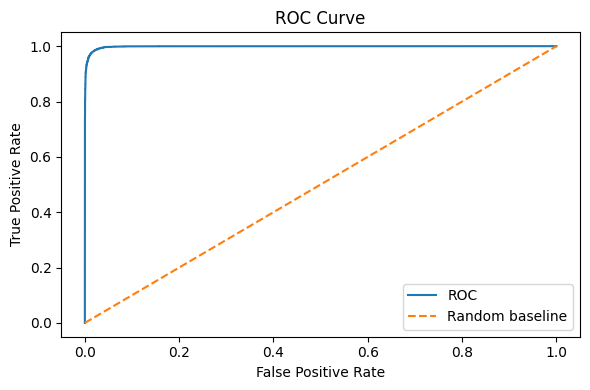

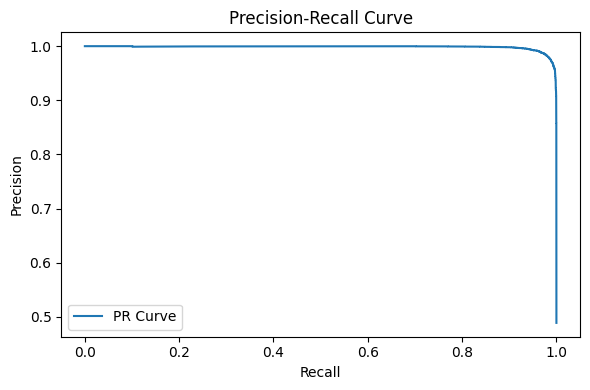

XGBoost - Test


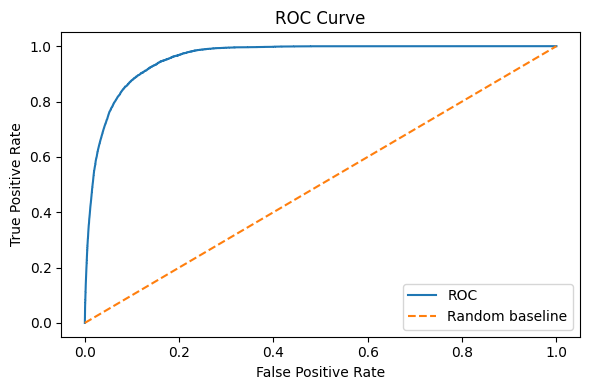

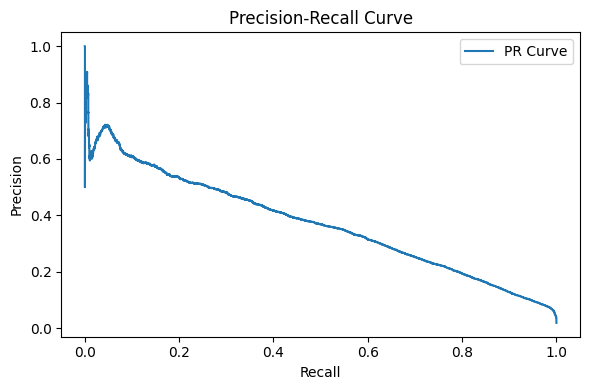

Saved shape: (331185,)


In [17]:
# Plot ROC and PR curves using reusable plotting helpers
from plotting import plot_roc_curve, plot_pr_curve

print("Logistic Regression - Validation")
plot_roc_curve(y_val, val_scores_lr)
plot_pr_curve(y_val, val_scores_lr)

print("Logistic Regression - Test")
plot_roc_curve(y_test, test_scores_lr)
plot_pr_curve(y_test, test_scores_lr)

print("XGBoost - Validation")
plot_roc_curve(y_val, val_scores_xgb)
plot_pr_curve(y_val, val_scores_xgb)

print("XGBoost - Test")
plot_roc_curve(y_test, test_scores_xgb)
plot_pr_curve(y_test, test_scores_xgb)

# Save XGBoost test probabilities for ensemble notebook
import os
os.makedirs("../outputs", exist_ok=True)

test_probs = test_scores_xgb
np.save("../outputs/xgboost_probs.npy", test_probs)
print("Saved shape:", test_probs.shape)